## A. Signaux périodiques dans les résidus de bruit Wiener des images Firefly

**Modèle.** Chaque image observée $y_i$ s'écrit

$$y_i = x_i + w_i + \xi_i$$

| symbole | signification |
|---|---|
| $y_i$ | l'image observée (luminance) |
| $x_i$ | le contenu de la scène : objets, contours, textures |
| $w_i$ | la trace laissée par le générateur, supposée **commune** à toutes les images : $w_i = w$ |
| $\xi_i$ | un bruit aléatoire, indépendant d'une image à l'autre |

**Résidu.** Avec un débruiteur $D$ qui estime le contenu, $D(y_i) \approx x_i$ :

$$r_i = y_i - D(y_i) = \big(x_i - D(y_i)\big) + w + \xi_i \;\approx\; w + \xi_i$$

**Moyenne.** $w$ est le même partout ; le bruit et l'erreur sur le contenu se compensent :

$$\bar r_N = \frac1N \sum_{i=1}^N r_i = w + \frac1N\sum_{i=1}^N \xi_i + \frac1N\sum_{i=1}^N \big(x_i - D(y_i)\big) \;\xrightarrow[N\to\infty]{}\; w$$

Même étude que `notebook_1`, mais le débruiteur $D$ est celui de `filtering_functions.py`
(Wiener par ondelettes), **appliqué à chaque image avant de moyenner** (comme pour la PRNU),
au lieu d'un flou gaussien appliqué à la moyenne.

0. Charger les 1000 images Firefly $y_i$ (RGB) et les grouper par taille.
1. Calculer le résidu $r_i$ de chaque image.
2. Calculer $\bar r_N$ pour des tailles d'échantillon $N$ croissantes.
3. Calculer l'autocorrélation de $\bar r_N$ et lire les périodes de $w$.
4. Résumer les pics les plus forts dans un tableau.

In [1]:
import sys
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import convolve, gaussian_filter, maximum_filter

# Dossier du projet : on remonte jusqu'au dossier qui contient pyproject.toml.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))
import filtering_functions as filtering  # noqa: E402

# filtering_functions utilise des API dépréciées (scipy.ndimage.filters, ndarray.shape = ...).
warnings.filterwarnings("ignore", category=DeprecationWarning)

RESULTS_DIR = PROJECT_ROOT / "results"
FIREFLY_DIR = PROJECT_ROOT / "data" / "synthbuster" / "synthbuster" / "firefly"
COCO_DIR = PROJECT_ROOT / "data" / "coco" / "test2017"
OUT = RESULTS_DIR / "02_wiener_residuals"  # cache des moyennes de résidus
OUT.mkdir(parents=True, exist_ok=True)
OUT_A = RESULTS_DIR / "01_mean_autocorr"  # moyennes de notebook_1 (pour comparaison)
rng = np.random.default_rng(0)  # même graine que notebook_1 -> mêmes échantillons

# Mode rapide : on ne garde que MAX_IMAGES images par taille (et par jeu simulé / COCO).
# None -> toutes les images (~40 min la première fois, ensuite relu depuis le cache).
MAX_IMAGES = 20

SAMPLE_SIZES = [10, 20, 50, 100]
LEVELS, SIGMA = 4, 5  # paramètres de extract_single (niveaux d'ondelettes, écart-type du bruit)
N_THREADS = 6  # extraction en parallèle (~2 s / image Firefly avec 6 threads)
LAG = 32
lags = np.arange(-LAG, LAG + 1)

# 0. L'extracteur `extract_single`

`extract_single(y, levels, sigma)` renvoie directement le résidu $r_i$, en trois étapes :

1. **`noise_extract`** (NoiseExtract, Binghamton) : décomposition de $y_i$ en ondelettes `db4` sur
   `levels` niveaux. Sur chaque coefficient de détail $c$, le résidu garde la part

   $$c \cdot \frac{\sigma^2}{\hat\sigma^2_{\text{loc}} + \sigma^2}$$

   où $\sigma^2$ est la variance supposée du bruit $\xi_i$ (`SIGMA`$^2$) et $\hat\sigma^2_{\text{loc}}$
   l'énergie locale du contenu (la plus petite sur des fenêtres 3, 5, 7, 9) :
   - zone plate ($\hat\sigma^2_{\text{loc}} \approx 0$) : $c$ passe entier dans $r_i$ (bruit $\xi_i$ ou trace $w$) ;
   - contour, texture ($\hat\sigma^2_{\text{loc}} \gg \sigma^2$) : $c$ reste dans $D(y_i)$, c'est du contenu $x_i$.

   L'approximation (basses fréquences) est mise à 0 : elle est entièrement attribuée au contenu.
   Fait canal par canal.
2. **`rgb2gray`** : passage en luminance.
3. **`wiener_dft`** : le même filtre appliqué au **module de la FFT** de $r_i$.

⚠️ L'étape 3 sert, en PRNU, à retirer du résidu les composantes périodiques (grille JPEG, etc.) :
elle **atténue les pics du spectre**, c'est-à-dire potentiellement la trace $w$ que l'on cherche.
On garde donc deux résidus, calculés en une seule passe :

| variante | résidu $r_i$ |
|---|---|
| `noise_extract` | étapes 1 + 2 |
| `extract_single` | étapes 1 + 2 + 3 (= `filtering.extract_single`) |

In [2]:
VARIANTS = ["noise_extract", "extract_single"]


def load_rgb(path):
    with Image.open(path) as img:
        return np.asarray(img.convert("RGB"))


def residuals(y):
    """Les deux résidus r_i = y_i - D(y_i) d'une image, avant et après wiener_dft (luminance, float32)."""
    r = filtering.rgb2gray(filtering.noise_extract(y, LEVELS, SIGMA))
    return {"noise_extract": r, "extract_single": filtering.wiener_dft(r, r.std(ddof=1))}


def group_by_size(paths):
    """{(largeur, hauteur): [chemins]}, plus grand groupe en premier. Lit seulement les en-têtes."""
    groups = {}
    for p in paths:
        with Image.open(p) as img:
            groups.setdefault(img.size, []).append(p)
    return dict(sorted(groups.items(), key=lambda kv: -len(kv[1])))


paths = sorted(FIREFLY_DIR.glob("*.png"))
print(f"{len(paths)} images dans {FIREFLY_DIR}")

# Vérification : la variante "extract_single" est bien identique à filtering.extract_single.
y0 = load_rgb(paths[0])
r0 = residuals(y0)
assert np.allclose(r0["extract_single"], filtering.extract_single(y0, LEVELS, SIGMA))

1000 images dans C:\Users\henry\Desktop\Firefly-detection\data\synthbuster\synthbuster\firefly


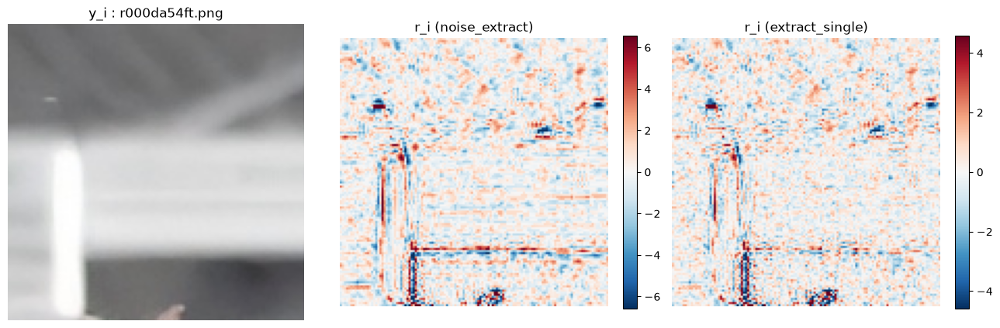

In [3]:
def crop_center(x, half):
    cy, cx = x.shape[0] // 2, x.shape[1] // 2
    return x[cy - half : cy + half + 1, cx - half : cx + half + 1]


# Aperçu : une image y_i et ses deux résidus r_i (carré central 128x128)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
axes[0].imshow(crop_center(y0, 64))
axes[0].set_title(f"y_i : {paths[0].name}")
for ax, v in zip(axes[1:], VARIANTS):
    c = crop_center(r0[v], 64)
    lim = np.percentile(np.abs(c), 99.5)
    im = ax.imshow(c, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"r_i ({v})")
    fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

# 1. Les groupes d'images

In [4]:
groups = group_by_size(paths)
# Ordre aléatoire (même tirage que notebook_1) : les N premières images forment un échantillon
# aléatoire, et chaque échantillon est inclus dans les suivants.
groups = {size: [group[i] for i in rng.permutation(len(group))] for size, group in groups.items()}
groups = {size: group[:MAX_IMAGES] for size, group in groups.items()}  # mode rapide
sizes = list(groups)
pd.DataFrame(
    [(f"{w}x{h}", len(p)) for (w, h), p in groups.items()],
    columns=["taille (largeur x hauteur, px)", "nombre d'images"],
).style.hide(axis="index").set_caption("Images Firefly regroupées par taille")

"taille (largeur x hauteur, px)",nombre d'images
2304x1792,20
1792x2304,20
2048x2048,20
2688x1536,20


# 2. Moyenne des résidus $\bar r_N$

$$\bar r_N = \frac1N \sum_{i=1}^N r_i = w + \frac1N\sum_{i=1}^N \xi_i + \frac1N\sum_{i=1}^N \big(x_i - D(y_i)\big)$$

Les deux derniers termes changent d'une image à l'autre et décroissent en $1/\sqrt N$ ; il doit
rester $w$. (Le débruiteur n'est pas parfait : il peut aussi retirer une partie de $w$, par exemple
ses basses fréquences.) Le calcul complet prend ~1 h la première fois ; les moyennes sont ensuite
relues depuis `results/02_wiener_residuals/`.

In [5]:
CHUNK = 4 * N_THREADS


def running_residual_means(paths, checkpoints):
    """{(variante, n): r̄_n, moyenne des résidus des n premières images}, en une seule passe."""
    checkpoints = sorted(set(checkpoints))
    todo = paths[: checkpoints[-1]]
    acc = dict.fromkeys(VARIANTS)
    means, k = {}, 0
    with ThreadPoolExecutor(N_THREADS) as pool:
        for start in range(0, len(todo), CHUNK):
            for res in pool.map(lambda p: residuals(load_rgb(p)), todo[start : start + CHUNK]):
                k += 1
                for v in VARIANTS:
                    acc[v] = res[v].astype(np.float64) if acc[v] is None else acc[v] + res[v]
                if k in checkpoints:
                    for v in VARIANTS:
                        means[v, k] = (acc[v] / k).astype(np.float32)
    return means


def cached_residual_means(size, paths, ns):
    files = {(v, n): OUT / f"{v}_{size[0]}x{size[1]}_n{n}.npy" for v in VARIANTS for n in ns}
    if all(f.exists() for f in files.values()):
        return {key: np.load(f) for key, f in files.items()}
    t0 = time.time()
    means = running_residual_means(paths, ns)
    for key, m in means.items():
        np.save(files[key], m)
    print(f"  {size[0]}x{size[1]} : {max(ns)} images en {time.time() - t0:.0f} s")
    return means


means = {}  # (variante, taille, N) -> r̄_N
sample_ns = {}  # taille -> liste des N
for size, group in groups.items():
    sample_ns[size] = sorted({n for n in SAMPLE_SIZES if n < len(group)} | {len(group)})
    for (v, n), m in cached_residual_means(size, group, sample_ns[size]).items():
        means[v, size, n] = m
    print(f"{size[0]}x{size[1]}: N = {sample_ns[size]}")

n_cols = max(len(ns) for ns in sample_ns.values())

2304x1792: N = [10, 20]
1792x2304: N = [10, 20]
2048x2048: N = [10, 20]
2688x1536: N = [10, 20]


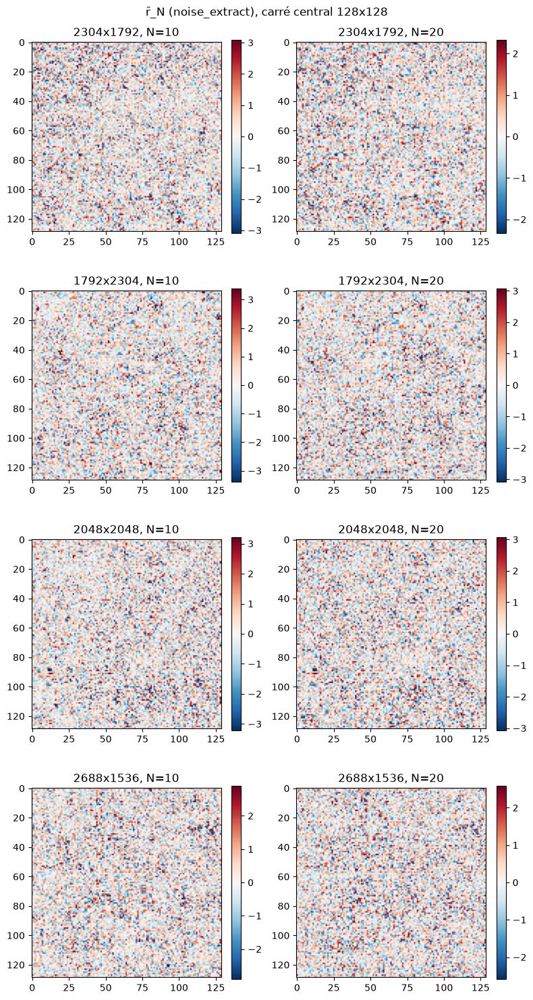

In [6]:
def plot_crops(variant):
    """Carré central 128x128 de la moyenne des résidus : une ligne par taille, une colonne par N."""
    fig, axes = plt.subplots(len(sizes), n_cols, figsize=(4.0 * n_cols, 3.8 * len(sizes)), squeeze=False)
    for row, size in zip(axes, sizes):
        for ax in row[len(sample_ns[size]) :]:
            ax.axis("off")
        for ax, n in zip(row, sample_ns[size]):
            c = crop_center(means[variant, size, n], 64)
            lim = np.percentile(np.abs(c), 99.5)
            im = ax.imshow(c, cmap="RdBu_r", vmin=-lim, vmax=lim)
            ax.set_title(f"{size[0]}x{size[1]}, N={n}")
            fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"r̄_N ({variant}), carré central 128x128")
    fig.tight_layout()
    plt.show()


plot_crops("noise_extract")

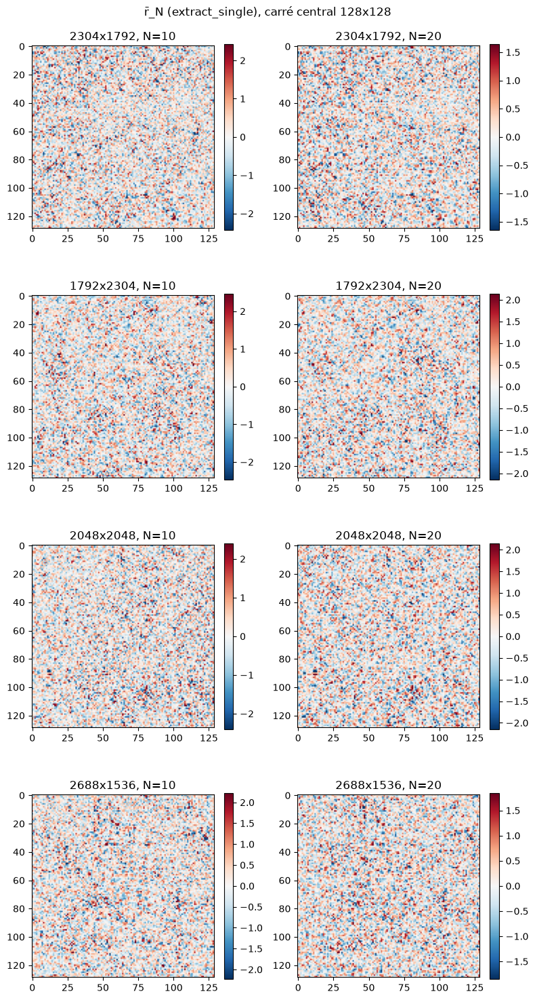

In [7]:
plot_crops("extract_single")

# 3. Autocorrélation

Si $\bar r_N \approx w$, l'autocorrélation de $\bar r_N$ montre la structure de $w$ : un motif de
période $p$ donne des pics aux décalages multiples de $p$. Comme dans `notebook_1`
(théorème de Wiener-Khinchin), avec $\mu$ la moyenne de $\bar r_N$ et $(u, v)$ les pixels :

$$
R(\Delta u, \Delta v) = \frac{\sum_{u,v} \big(\bar r_N(u,v) - \mu\big)\big(\bar r_N(u+\Delta u, v+\Delta v) - \mu\big)}{\sum_{u,v} \big(\bar r_N(u,v) - \mu\big)^2}
= \frac{\mathcal F^{-1}\{|\mathcal F\{\bar r_N - \mu\}|^2\}}{\sum (\bar r_N - \mu)^2}
$$

(Dans les graphiques, $\Delta y$ = décalage vertical, $\Delta x$ = décalage horizontal, en pixels.)

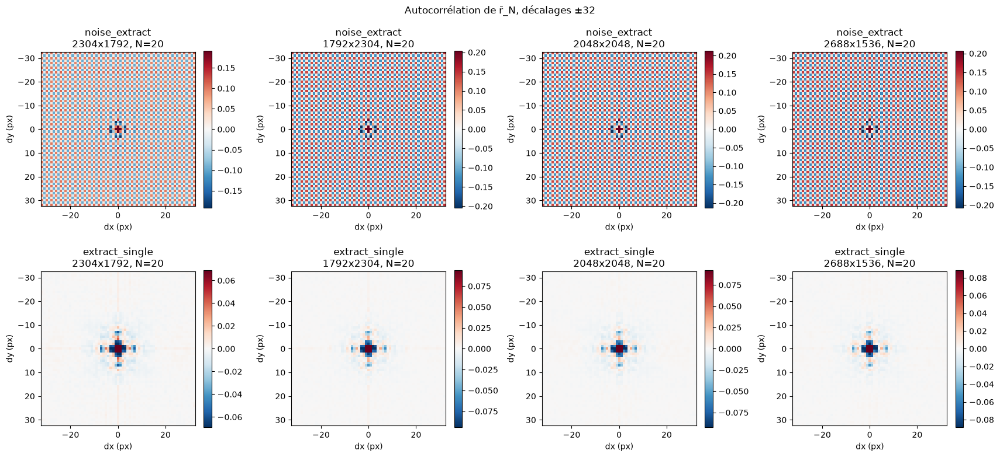

In [8]:
def autocorrelation(x):
    x = x - x.mean()
    r = np.fft.ifft2(np.abs(np.fft.fft2(x)) ** 2).real
    return np.fft.fftshift(r / r.flat[0])


def zoom_ylim(ax, curves, exclude=1):
    """Échelle verticale réglée sur les décalages non nuls (le pic en 0 vaut 1)."""
    m = max(np.abs(c[np.abs(lags) > exclude]).max() for c in curves)
    ax.set_ylim(-1.2 * m, 1.2 * m)


acf = {key: crop_center(autocorrelation(m), LAG) for key, m in means.items()}

# Cartes 2D avec toutes les images : une ligne par variante, une colonne par taille
ext = (-LAG - 0.5, LAG + 0.5, LAG + 0.5, -LAG - 0.5)
fig, axes = plt.subplots(len(VARIANTS), len(sizes), figsize=(4.3 * len(sizes), 4 * len(VARIANTS)), squeeze=False)
for row, v in zip(axes, VARIANTS):
    for ax, size in zip(row, sizes):
        r = acf[v, size, sample_ns[size][-1]]
        hidden = r.copy()
        hidden[LAG - 2 : LAG + 3, LAG - 2 : LAG + 3] = 0  # on masque le pic en 0 pour l'échelle
        lim = np.abs(hidden).max()
        im = ax.imshow(r, cmap="RdBu_r", vmin=-lim, vmax=lim, extent=ext)
        ax.set(title=f"{v}\n{size[0]}x{size[1]}, N={sample_ns[size][-1]}", xlabel="dx (px)", ylabel="dy (px)")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"Autocorrélation de r̄_N, décalages ±{LAG}")
fig.tight_layout()
plt.show()

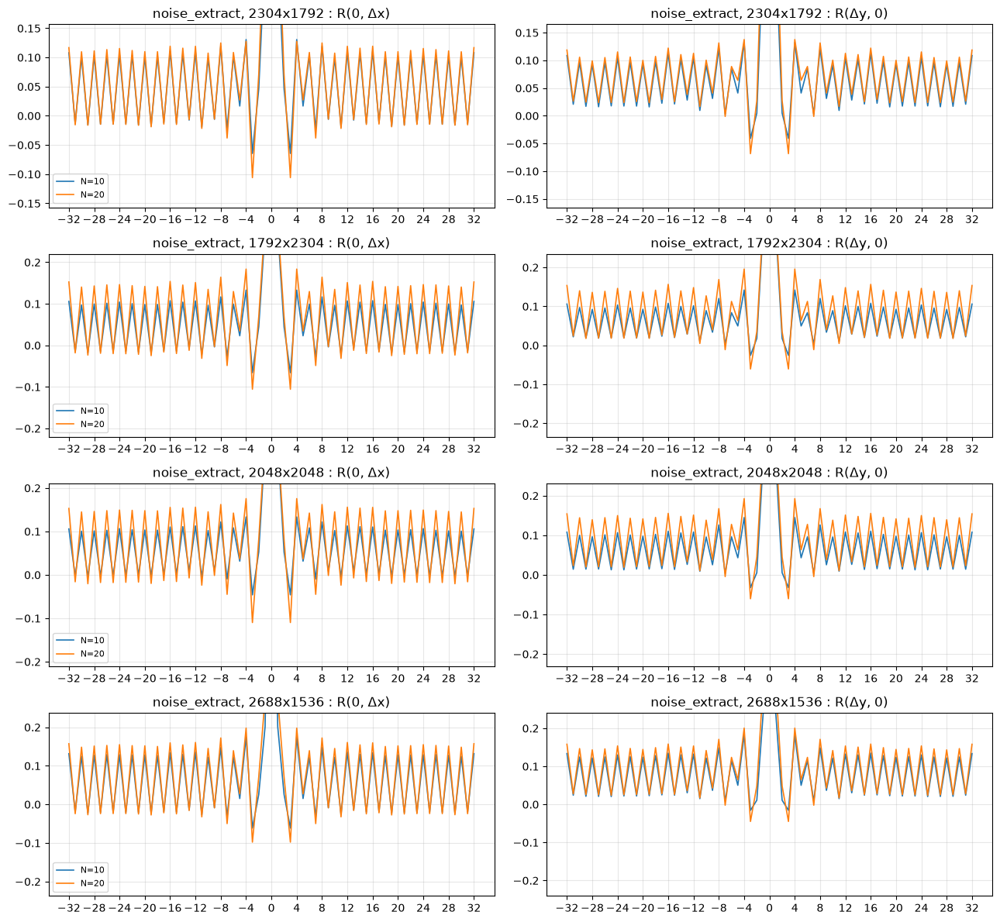

In [9]:
# Autocorrélation selon les axes, pour chaque N
def plot_axis_profiles(variant):
    fig, axes = plt.subplots(len(sizes), 2, figsize=(13, 3 * len(sizes)), squeeze=False)
    for row, size in zip(axes, sizes):
        curves_x = [acf[variant, size, n][LAG, :] for n in sample_ns[size]]
        curves_y = [acf[variant, size, n][:, LAG] for n in sample_ns[size]]
        for n, cx, cy in zip(sample_ns[size], curves_x, curves_y):
            row[0].plot(lags, cx, lw=1.2, label=f"N={n}")
            row[1].plot(lags, cy, lw=1.2, label=f"N={n}")
        row[0].set_title(f"{variant}, {size[0]}x{size[1]} : R(0, Δx)")
        row[1].set_title(f"{variant}, {size[0]}x{size[1]} : R(Δy, 0)")
        for ax, curves in zip(row, (curves_x, curves_y)):
            zoom_ylim(ax, curves)
            ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
            ax.grid(alpha=0.3)
        row[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


plot_axis_profiles("noise_extract")

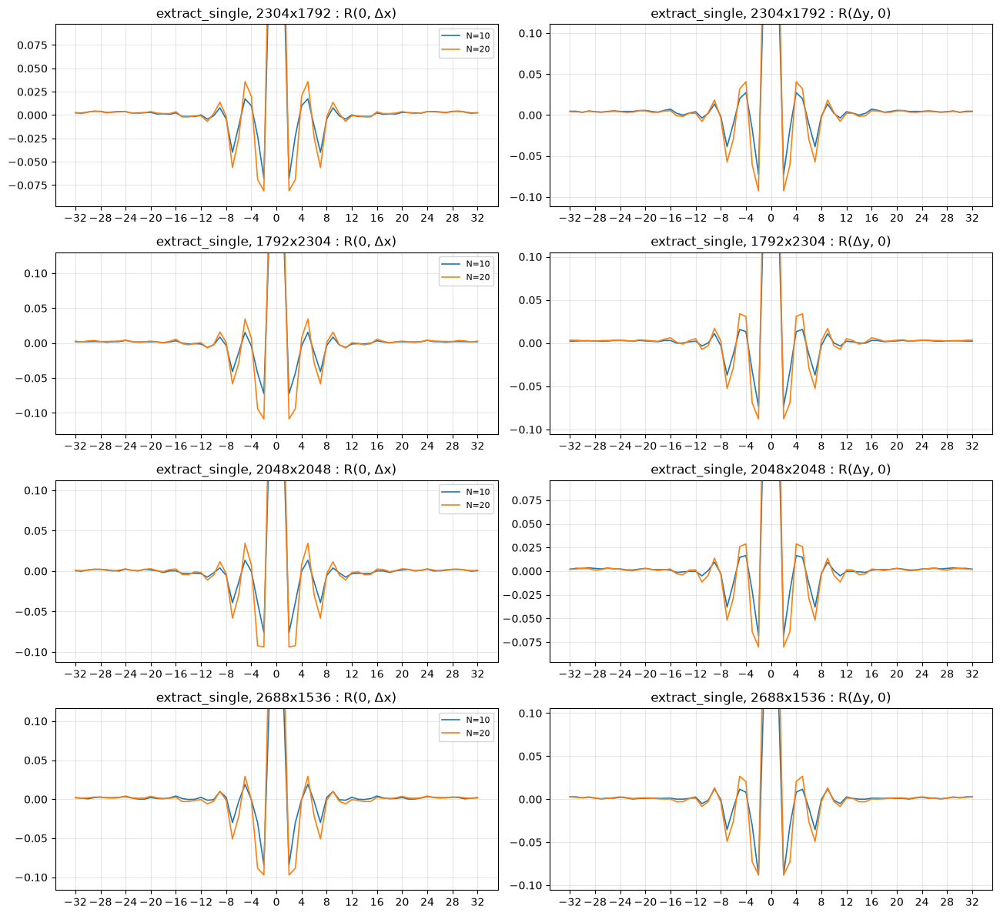

In [10]:
plot_axis_profiles("extract_single")

## Comparaison avec le filtre gaussien de `notebook_1`

Dans `notebook_1`, le débruiteur est un flou gaussien $G_1$ ($\sigma = 1$) appliqué **à la moyenne**
des images : $\bar y_N - G_1 * \bar y_N$ (moyennes relues depuis `results/01_mean_autocorr/`).
Ici, le débruiteur Wiener est appliqué **à chaque image** : $\bar r_N = \frac1N\sum_i \big(y_i - D(y_i)\big)$.

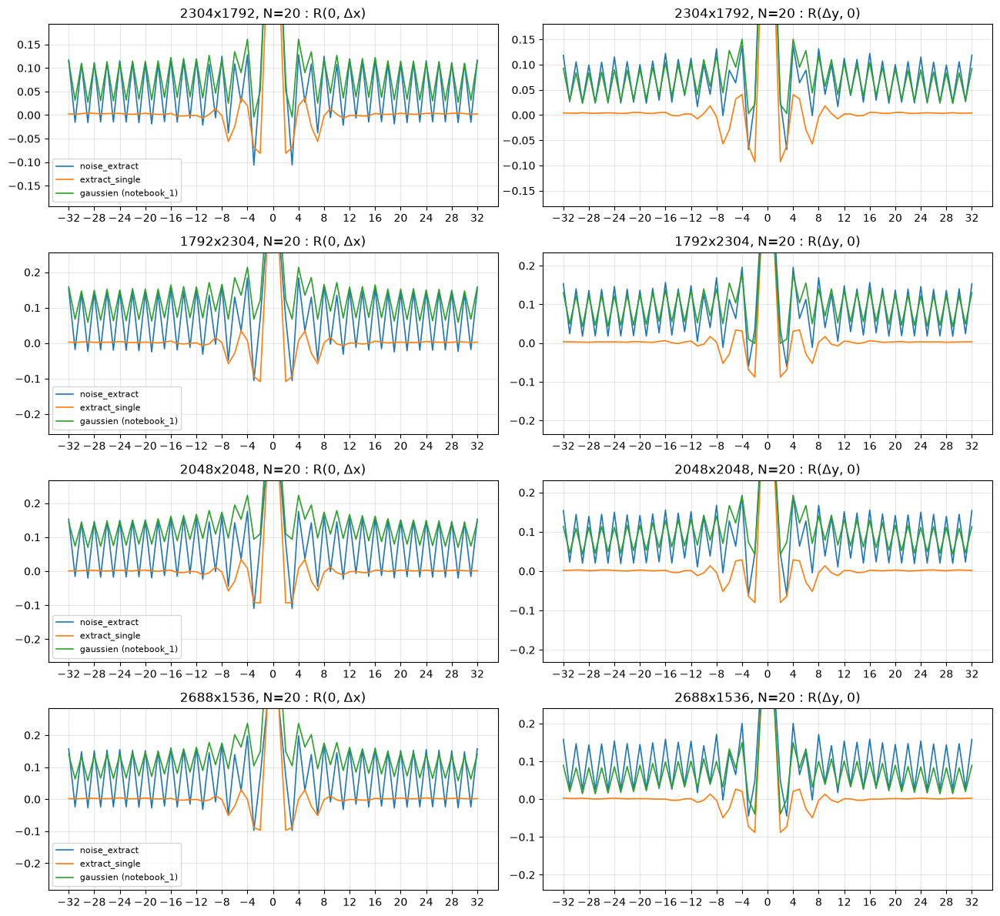

In [11]:
def gaussian_residual(x, sigma=1):
    return x - gaussian_filter(x, sigma, mode="wrap", radius=3)


fig, axes = plt.subplots(len(sizes), 2, figsize=(13, 3 * len(sizes)), squeeze=False)
for row, size in zip(axes, sizes):
    n = sample_ns[size][-1]
    curves = {v: acf[v, size, n] for v in VARIANTS}
    f_a = OUT_A / f"mean_{size[0]}x{size[1]}_n{n}.npy"
    if f_a.exists():
        curves["gaussien (notebook_1)"] = crop_center(autocorrelation(gaussian_residual(np.load(f_a))), LAG)
    for name, r in curves.items():
        row[0].plot(lags, r[LAG, :], lw=1.2, label=name)
        row[1].plot(lags, r[:, LAG], lw=1.2, label=name)
    row[0].set_title(f"{size[0]}x{size[1]}, N={n} : R(0, Δx)")
    row[1].set_title(f"{size[0]}x{size[1]}, N={n} : R(Δy, 0)")
    for ax, axis in zip(row, (0, 1)):
        zoom_ylim(ax, [r[LAG, :] if axis == 0 else r[:, LAG] for r in curves.values()])
        ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
        ax.grid(alpha=0.3)
    row[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Spectre de $\bar r_N$

Une trace $w$ de période $p$ donne des raies aux fréquences multiples de $1/p$ (cycles/px). C'est
ici que l'effet de `wiener_dft` se voit directement.

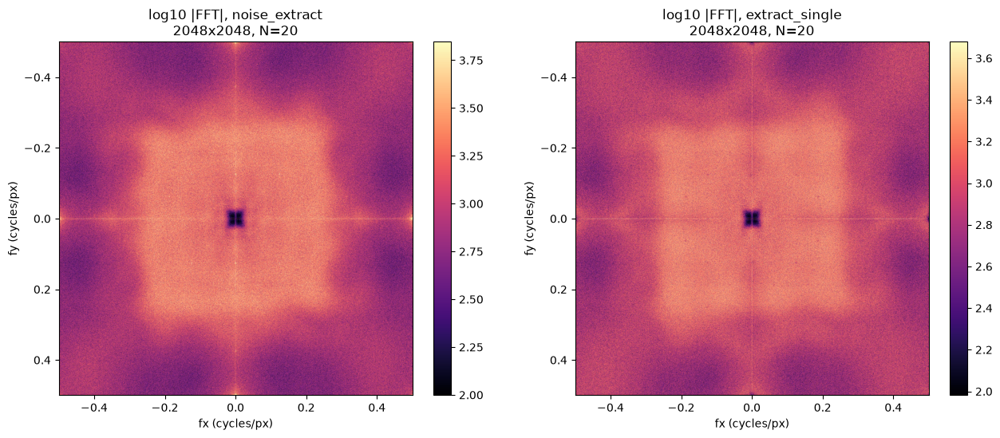

In [12]:
size_ff = (2048, 2048)
n_ff = sample_ns[size_ff][-1]

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(6.5 * len(VARIANTS), 5.5))
for ax, v in zip(axes, VARIANTS):
    m = means[v, size_ff, n_ff]
    spec = np.log10(np.abs(np.fft.fftshift(np.fft.fft2(m - m.mean()))) + 1e-6)
    lo, hi = np.percentile(spec, [1, 99.95])
    im = ax.imshow(spec, cmap="magma", vmin=lo, vmax=hi, extent=(-0.5, 0.5, 0.5, -0.5))
    ax.set(title=f"log10 |FFT|, {v}\n2048x2048, N={n_ff}", xlabel="fx (cycles/px)", ylabel="fy (cycles/px)")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

# Comparaison avec un bruit blanc

Image témoin $y = 128 + \xi$ : pas de contenu ($x = 0$, à une constante près), pas de trace
($w = 0$), seulement un bruit blanc $\xi$. Ce qui apparaît dans son autocorrélation vient du
débruiteur $D$ lui-même, pas d'une trace.

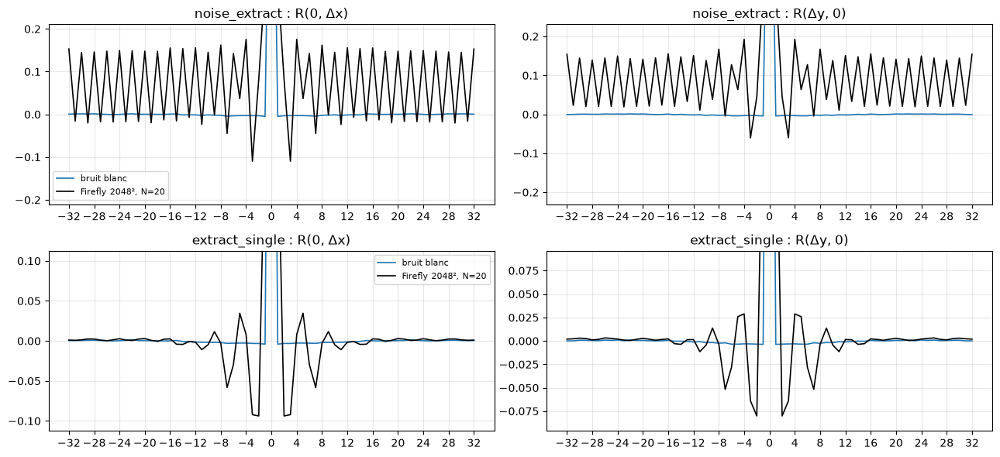

In [13]:
mean_ff = {v: means[v, size_ff, n_ff] for v in VARIANTS}
# Bruit blanc à l'échelle des niveaux de gris (le seuil du Wiener, SIGMA = 5, en dépend)
noise_ctrl = 128 + 20 * np.random.default_rng(1).standard_normal(mean_ff["noise_extract"].shape)
res_ctrl = residuals(noise_ctrl)

fig, axes = plt.subplots(len(VARIANTS), 2, figsize=(13, 3 * len(VARIANTS)), squeeze=False)
for row, v in zip(axes, VARIANTS):
    curves = {"bruit blanc": crop_center(autocorrelation(res_ctrl[v]), LAG),
              f"Firefly 2048², N={n_ff}": crop_center(autocorrelation(mean_ff[v]), LAG)}
    for (label, r), color in zip(curves.items(), ("tab:blue", "black")):
        row[0].plot(lags, r[LAG, :], lw=1.2, color=color, label=label)
        row[1].plot(lags, r[:, LAG], lw=1.2, color=color, label=label)
    row[0].set_title(f"{v} : R(0, Δx)")
    row[1].set_title(f"{v} : R(Δy, 0)")
    for ax, axis in zip(row, (0, 1)):
        zoom_ylim(ax, [r[LAG, :] if axis == 0 else r[:, LAG] for r in curves.values()])
        ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
        ax.grid(alpha=0.3)
    row[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [14]:
rows = []
for v in VARIANTS:
    for label, x in {"bruit blanc": res_ctrl[v], f"Firefly 2048², N={n_ff}": mean_ff[v]}.items():
        y = x - x.mean()
        rows.append((v, label, *[round(y[p::2, q::2].mean(), 4) for p in (0, 1) for q in (0, 1)], round(y.std(), 4)))
pd.DataFrame(rows, columns=["résidu", "image",
                            "moyenne des pixels : ligne paire, colonne paire",
                            "moyenne des pixels : ligne paire, colonne impaire",
                            "moyenne des pixels : ligne impaire, colonne paire",
                            "moyenne des pixels : ligne impaire, colonne impaire",
                            "écart-type du résidu (échelle)"]).style.hide(axis="index").format(precision=4).set_caption(
    "Motif 2x2 moyen du résidu (moyenne globale retirée) : "
    "moyenne des pixels selon la parité de leur ligne et de leur colonne"
)

résidu,image,"moyenne des pixels : ligne paire, colonne paire","moyenne des pixels : ligne paire, colonne impaire","moyenne des pixels : ligne impaire, colonne paire","moyenne des pixels : ligne impaire, colonne impaire",écart-type du résidu (échelle)
noise_extract,bruit blanc,-0.0001,-0.0003,0.0012,-0.0008,1.6403
noise_extract,"Firefly 2048², N=20",-0.0215,-0.3815,0.4929,-0.0899,0.8792
extract_single,bruit blanc,-0.0001,-0.0003,0.0012,-0.0008,1.6055
extract_single,"Firefly 2048², N=20",-0.0012,0.0004,0.0020,-0.0011,0.6253


**Pics les plus forts**

In [15]:
def peaks(r, k=8, exclude=2):
    c = r.shape[0] // 2
    ys, xs = np.nonzero((r == maximum_filter(r, size=3, mode="wrap")) & (r > 0))
    out = [(y - c, x - c, r[y, x]) for y, x in zip(ys, xs)
           if max(abs(y - c), abs(x - c)) > exclude and (y - c, x - c) > (0, 0)]
    return sorted(out, key=lambda p: -p[2])[:k]


rows = []
for (v, size, n), r in acf.items():
    for rank, (dy, dx, val) in enumerate(peaks(r), 1):
        rows.append((v, f"{size[0]}x{size[1]}", n, rank, dy, dx, round(val, 3)))
df_peaks = pd.DataFrame(rows, columns=["variant", "size", "N", "rank", "dy", "dx", "R"])
(df_peaks.pivot_table(index=["variant", "size", "N"], columns="rank", values="R")
 .rename(columns=lambda k: f"pic n°{k}")
 .rename_axis(index=["résidu", "taille", "N (images moyennées)"], columns=None)
 .style.format(precision=3)
 .set_caption("Hauteur R des 8 plus grands pics de l'autocorrélation, du plus haut (n°1) au plus bas "
              "(décalages à plus de 2 px de l'origine, un seul pic par paire ±)"))

In [16]:
# Position des pics, avec toutes les images de chaque taille
full = df_peaks[df_peaks.N == df_peaks.groupby(["variant", "size"]).N.transform("max")]
(full.pivot_table(index=["variant", "size"], columns="rank", values=["dy", "dx"], aggfunc="first")[["dy", "dx"]]
 .rename(columns={"dy": "Δy : décalage vertical (px)", "dx": "Δx : décalage horizontal (px)"}, level=0)
 .rename(columns=lambda k: f"pic n°{k}", level=1)
 .rename_axis(index=["résidu", "taille"], columns=[None, None])
 .style.set_caption("Position (Δy, Δx) des mêmes pics, avec toutes les images de chaque taille"))

## B. Effet des différentes méthodes d'upsampling

On refait la partie A sur des images simulées, où l'on sait tout :
1. on tire $N$ images de bruit blanc $z_i$, 512×512 (moyenne 128, écart-type 20, à l'échelle des
   niveaux de gris) : pas de contenu, aucune structure au départ ;
2. on les upsample ×2 (→ 1024×1024) avec une méthode $U$ donnée : $y_i = U(z_i)$ ;
3. comme en A : résidu $r_i = y_i - D(y_i)$ (deux variantes), moyenne $\bar r_N$, autocorrélation.

Si Firefly upsample ses images, la trace $w$ devrait ressembler à ce que $U$ produit ici.

On compare au profil de Firefly (2048×2048, toutes les images, courbe noire).

In [17]:
N_IMG, N_LOW, MU, STD = min(50, MAX_IMAGES or 50), 512, 128.0, 20.0
acf_ff = {v: acf[v, size_ff, n_ff] for v in VARIANTS}


def simulate(upsample):
    """Partie A sur N_IMG bruits upsamplés : {variante: autocorrélation de la moyenne des résidus}."""
    lows = [MU + STD * rng.standard_normal((N_LOW, N_LOW)) for _ in range(N_IMG)]
    acc = dict.fromkeys(VARIANTS, 0.0)
    with ThreadPoolExecutor(N_THREADS) as pool:
        for res in pool.map(lambda x: residuals(upsample(x)), lows):
            for v in VARIANTS:
                acc[v] = acc[v] + res[v]
    return {v: crop_center(autocorrelation(acc[v] / N_IMG), LAG) for v in VARIANTS}


def plot_profiles(sims, title):
    """sims : {méthode: {variante: acf}}. Une ligne par variante, Firefly en noir."""
    fig, axes = plt.subplots(len(VARIANTS), 2, figsize=(13, 3.5 * len(VARIANTS)), squeeze=False)
    for row, v in zip(axes, VARIANTS):
        curves = {name: s[v] for name, s in sims.items()}
        for name, r in curves.items():
            row[0].plot(lags, r[LAG, :], lw=1.2, label=name)
            row[1].plot(lags, r[:, LAG], lw=1.2, label=name)
        row[0].plot(lags, acf_ff[v][LAG, :], lw=2, color="black", label="Firefly 2048²")
        row[1].plot(lags, acf_ff[v][:, LAG], lw=2, color="black", label="Firefly 2048²")
        row[0].set(title=f"{title}, {v} : R(0, Δx)", xlabel="Δx (px)")
        row[1].set(title=f"{title}, {v} : R(Δy, 0)", xlabel="Δy (px)")
        all_r = [*curves.values(), acf_ff[v]]
        zoom_ylim(row[0], [r[LAG, :] for r in all_r])
        zoom_ylim(row[1], [r[:, LAG] for r in all_r])
        for ax in row:
            ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
            ax.grid(alpha=0.3)
        row[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

## 1. Interpolation classique

Chaque pixel de sortie est une moyenne pondérée des pixels d'entrée voisins ; les poids
(le noyau : nearest, bilinear, bicubic, Lanczos) sont fixes et normalisés à somme 1.

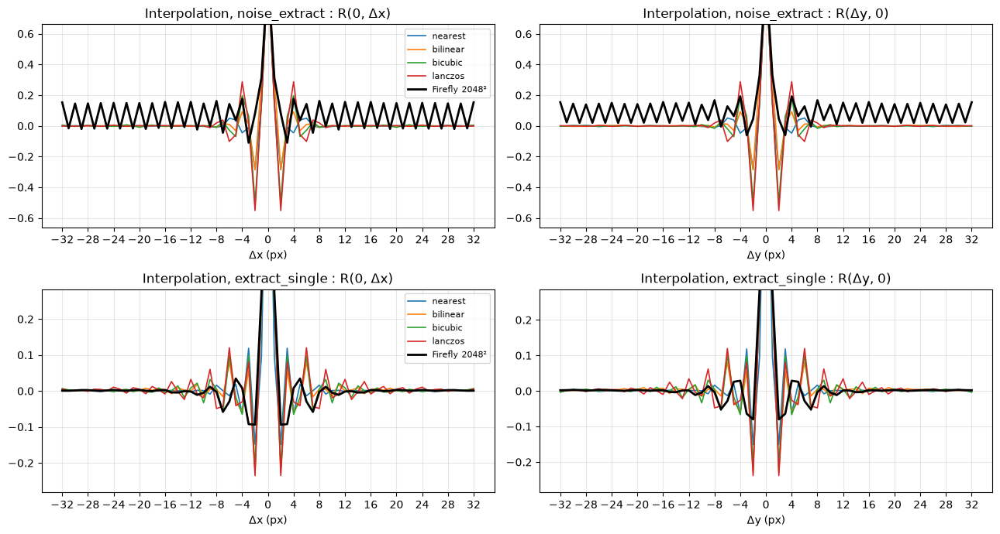

In [18]:
INTERPOLATIONS = {"nearest": Image.NEAREST, "bilinear": Image.BILINEAR,
                  "bicubic": Image.BICUBIC, "lanczos": Image.LANCZOS}


def interpolate(x, method):
    img = Image.fromarray(x.astype(np.float32))
    return np.asarray(img.resize((2 * x.shape[1], 2 * x.shape[0]), INTERPOLATIONS[method]), dtype=np.float64)


plot_profiles({m: simulate(lambda x, m=m: interpolate(x, m)) for m in INTERPOLATIONS}, "Interpolation")

## 2. Convolution transposée

Mêmes noyaux que `notebook_1` (bilinéaire 4×4, uniforme 3×3, aléatoire 3×3), normalisés à $\sum K = 4$ :

$$u[2m,\, 2l] = x[m,\, l], \quad u = 0 \text{ ailleurs}, \qquad y = u * K$$

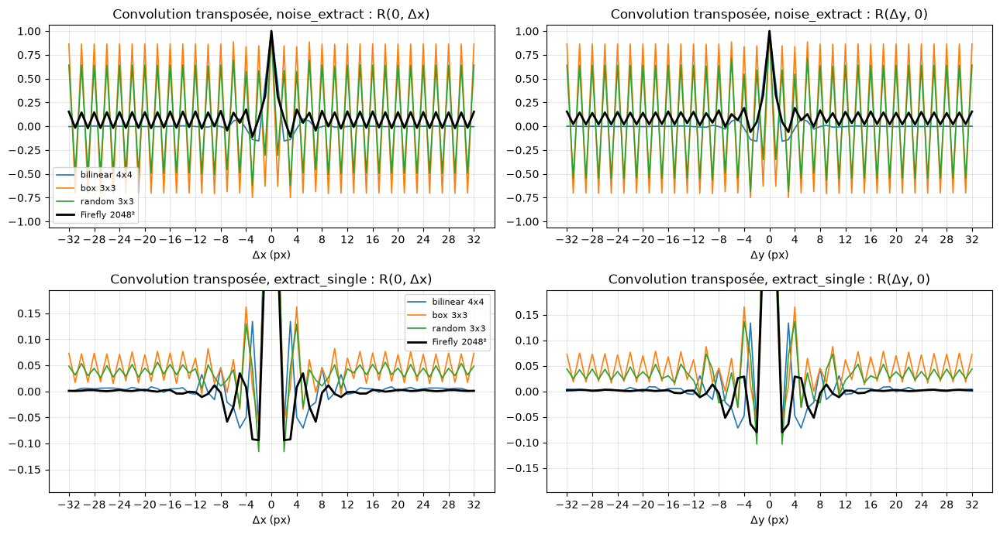

In [19]:
def transposed_conv(x, kernel):
    u = np.zeros((2 * x.shape[0], 2 * x.shape[1]))
    u[::2, ::2] = x  # insertion de zéros
    return convolve(u, kernel, mode="wrap")


h = np.array([1, 3, 3, 1]) / 4
k_random = np.random.default_rng(42).normal(1, 0.5, (3, 3))
TCONV_KERNELS = {"bilinear 4x4": np.outer(h, h),
                 "box 3x3": np.ones((3, 3)) * 4 / 9,
                 "random 3x3": k_random * 4 / k_random.sum()}

plot_profiles({name: simulate(lambda x, K=K: transposed_conv(x, K)) for name, K in TCONV_KERNELS.items()},
              "Convolution transposée")

## C. Comparaison avec des images réelles (COCO)

On réutilise les images COCO `test2017` déjà téléchargées par `notebook_1` (partie C) dans
`data/coco/test2017/`, à la taille la plus fréquente. Ce sont de vraies photos : pas de trace de
générateur ($w = 0$ attendu), donc $\bar r_N$ ne devrait contenir que ce qui reste de bruit et de contenu.

⚠️ Les images COCO sont des **JPEG** : la compression par blocs 8×8 peut laisser un pic à
$\Delta = 8$. `wiener_dft` est justement conçu pour atténuer ce type de pic.

20 images COCO en 640x480


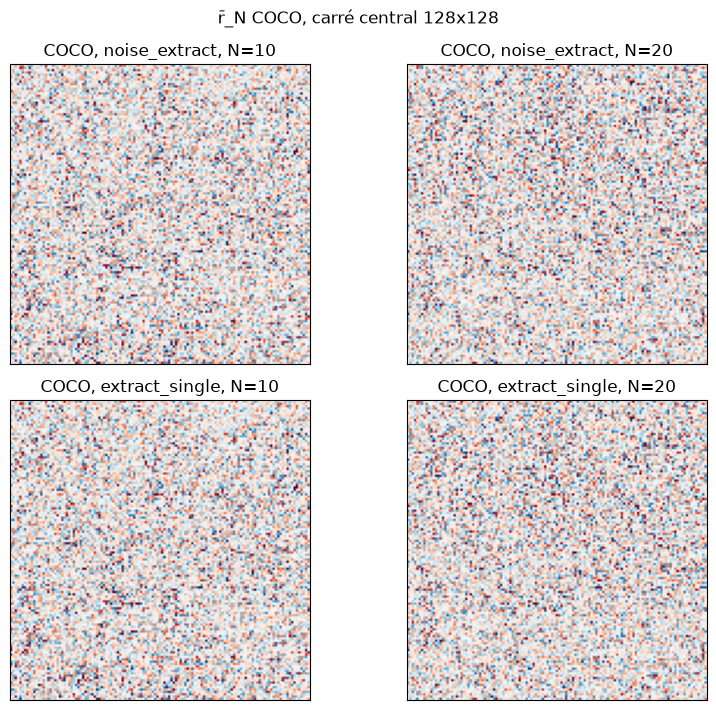

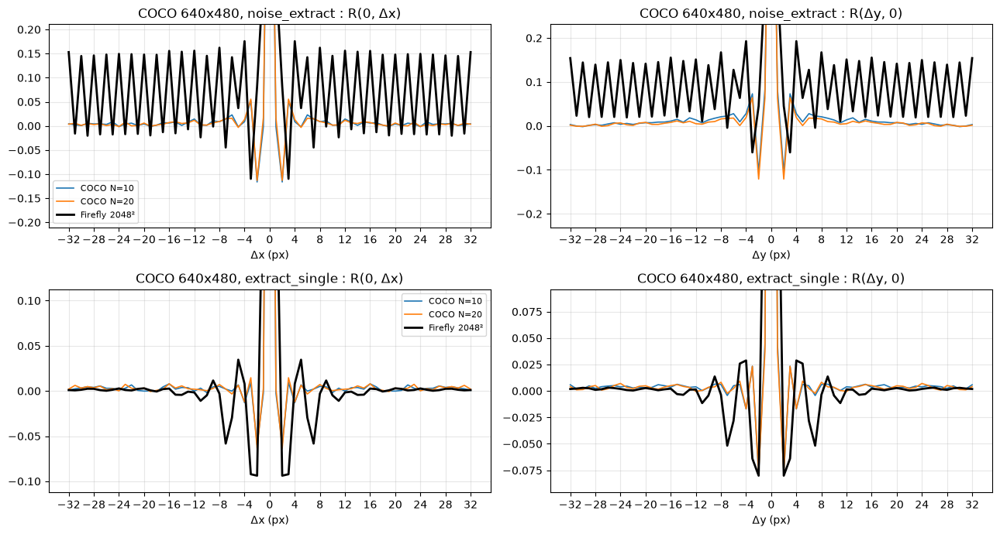

In [20]:
coco_files = sorted(COCO_DIR.glob("*.jpg"))
assert coco_files, f"Aucune image dans {COCO_DIR} : lancer d'abord la partie C de notebook_1."
size_coco, coco_paths = next(iter(group_by_size(coco_files).items()))
coco_paths = coco_paths[:MAX_IMAGES]  # mode rapide
n_coco = len(coco_paths)
print(f"{n_coco} images COCO en {size_coco[0]}x{size_coco[1]}")

ns_coco = sorted({n for n in SAMPLE_SIZES if n < n_coco} | {n_coco})
means_coco = running_residual_means(coco_paths, ns_coco)

fig, axes = plt.subplots(len(VARIANTS), len(ns_coco), figsize=(4.3 * len(ns_coco), 3.6 * len(VARIANTS)), squeeze=False)
for row, v in zip(axes, VARIANTS):
    for ax, n in zip(row, ns_coco):
        c = crop_center(means_coco[v, n], 64)
        lim = np.percentile(np.abs(c), 99.5)
        ax.imshow(c, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set(title=f"COCO, {v}, N={n}", xticks=[], yticks=[])
fig.suptitle("r̄_N COCO, carré central 128x128")
fig.tight_layout()
plt.show()

sims_coco = {f"COCO N={n}": {v: crop_center(autocorrelation(means_coco[v, n]), LAG) for v in VARIANTS}
             for n in ns_coco}
plot_profiles(sims_coco, f"COCO {size_coco[0]}x{size_coco[1]}")